In [41]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import (confusion_matrix,accuracy_score,
recall_score,f1_score,roc_auc_score,precision_score)

In [42]:
df=pd.read_csv(r'C:\Users\USER\Desktop\5th sem\project1_daibatise\data\processed\mohammed_ajlan_p1w1_features.csv')

In [43]:
feature_cols = ["age","pregnancies","glucose","blood_pressure",
                "skin_thickness","insulin","bmi","diabetes_pedigree",
                "bmi_category","glucose_band"]
x = df[feature_cols].copy()
y = df["outcome"]
x

,age,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,bmi_category,glucose_band
0,79,0,124.000000,71.0,30.0,124.0,23.4,0.588,normal,prediabetic
1,37,0,153.000000,85.0,24.0,42.0,33.9,0.192,obese,diabetic
2,39,0,142.000000,68.0,22.0,159.0,26.9,0.777,overweight,diabetic
3,68,7,121.000000,88.0,26.0,124.0,29.0,1.217,overweight,prediabetic
4,75,0,107.000000,84.0,31.0,101.0,21.2,0.278,normal,prediabetic
...,...,...,...,...,...,...,...,...,...,...
945,64,2,117.855165,81.0,34.0,124.0,40.3,0.641,obese,prediabetic
946,71,0,140.000000,64.0,37.0,124.0,33.4,0.116,obese,diabetic
947,40,0,130.000000,73.0,26.0,258.0,20.1,0.709,normal,diabetic
948,52,4,123.000000,76.0,22.0,189.0,38.9,0.540,obese,prediabetic


In [44]:
x=pd.get_dummies(x,drop_first=True)
x.shape

(950, 13)

In [45]:
x_train,x_test,y_train,y_test= train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y)

In [46]:
scaler = StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [47]:
logreg = LogisticRegression(max_iter=1000).fit(x_train_scaled, y_train)
dtree = DecisionTreeClassifier(max_depth=3,random_state=42).fit(x_train, y_train)
knn = KNeighborsClassifier(n_neighbors=25).fit(x_train_scaled, y_train)



In [48]:
def score_row(name, pred,scores=None):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    r = {
        "model":name,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "f1": round(f1_score(y_test, pred, zero_division=0), 4),
        "found": int(tp),
        "missed": int(fn),
        "false_alarms": int(fp)}
    if scores is  not None :
        r["auc"] = round(roc_auc_score(y_test,scores),4)
    return r
print("Train:", x_train.shape, " Test:", x_test.shape)
print("Diabetic patients in the test set:", int(np.sum(y_test)), "of", len(y_test))

for nm, m, Xt in [
    ("Logistic Regression", logreg, x_test_scaled),
    ("Decision Tree (d=3)", dtree, x_test),
    ("KNN (k=25)", knn, x_test_scaled)
]:
    print(f"{nm:22s} accuracy {accuracy_score(y_test, m.predict(Xt)):.4f}")

Train: (760, 13)  Test: (190, 13)
Diabetic patients in the test set: 55 of 190
Logistic Regression    accuracy 0.7526
Decision Tree (d=3)    accuracy 0.7211
KNN (k=25)             accuracy 0.7474


restate the target you are aiming at


In [49]:
TARGET_RECALL = 0.70
GUARD_F1 = 0.50
BEST_SO_FAR = 0.6182

print("PROJECT METRIC : recall  (guard: F1 >=", GUARD_F1, ")")
print("TARGET          : recall >=", TARGET_RECALL)
print("BEST SO FAR     :", BEST_SO_FAR, "(Week 5 baseline at threshold 0.30)")
print("GAP TO CLOSE    :", round(TARGET_RECALL - BEST_SO_FAR, 4))

PROJECT METRIC : recall  (guard: F1 >= 0.5 )
TARGET          : recall >= 0.7
BEST SO FAR     : 0.6182 (Week 5 baseline at threshold 0.30)
GAP TO CLOSE    : 0.0818


SVM (Support Vector Machine) is a machine learning algorithm used mainly for classification.
It finds the best boundary (hyperplane) that separates different classes of data with the maximum possible margin between them.

train an svm with default settings

In [50]:
from sklearn.svm import SVC

svm_rbf = SVC(random_state=42)
svm_rbf.fit(x_train_scaled, y_train)

pred_rbf = svm_rbf.predict(x_test_scaled)

print("Fitted:", svm_rbf)
print("Patients flagged:", int(pred_rbf.sum()), "of", len(pred_rbf))

Fitted: SVC(random_state=42)
Patients flagged: 17 of 190


In [51]:
row_rbf= score_row("SVC rbf (default)",pred_rbf,
                   svm_rbf.decision_function(x_test_scaled))
print(pd.DataFrame([row_rbf]).to_string(index=False))
print()
print("target recall:", TARGET_RECALL,"| best so far:",BEST_SO_FAR)
print("this model :", row_rbf["recall"])

            model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
SVC rbf (default)    0.7263     0.5882  0.1818 0.2778     10      45             7 0.6443

target recall: 0.7 | best so far: 0.6182
this model : 0.1818


try a straight boundary instead

In [52]:
svm_liner = SVC(kernel='linear',random_state=42)
svm_liner.fit(x_train_scaled,y_train)                       
pred_liner = svm_liner.predict(x_test_scaled)
print("fitted:", svm_liner)
print("patients flagged:",int(pred_liner.sum()), "of", len(pred_liner))


fitted: SVC(kernel='linear', random_state=42)
patients flagged: 0 of 190


In [53]:
row_liner = score_row('SVC linear', pred_liner,svm_liner.decision_function(x_test_scaled))
print(pd.DataFrame([row_liner,row_rbf]).to_string(index=False))

            model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
       SVC linear    0.7105     0.0000  0.0000 0.0000      0      55             0 0.6919
SVC rbf (default)    0.7263     0.5882  0.1818 0.2778     10      45             7 0.6443


look closely at what the linear svm predicted

In [54]:
print("Patients the linear SVM flagged as diabetic:", int(pred_liner.sum()), "of", len(pred_liner))
print()
print("Linear SVM confusion matrix:")
print(confusion_matrix(y_test, pred_liner))
print()
print("Week 5 dummy model confusion matrix:*")
print(confusion_matrix(y_test, np.zeros_like(y_test)))
print()
print("Linear SVM accuracy :", round(accuracy_score(y_test, pred_liner), 4))
print("Dummy model accuracy:", round(accuracy_score(y_test, np.zeros_like(y_test)), 4))


Patients the linear SVM flagged as diabetic: 0 of 190

Linear SVM confusion matrix:
[[135   0]
 [ 55   0]]

Week 5 dummy model confusion matrix:*
[[135   0]
 [ 55   0]]

Linear SVM accuracy : 0.7105
Dummy model accuracy: 0.7105


learn what class_weight does?

Class weight tells a machine learning model to give more importance to certain classes, usually the minority class. It helps the model handle imbalanced datasets by penalizing mistakes on important or underrepresented classes more heavily.

refit both svms with balanced class weights

In [55]:
svm_rbf_bal = SVC(random_state=42, class_weight="balanced").fit(
    x_train_scaled, y_train
)

svm_lin_bal = SVC(kernel="linear", random_state=42,
                  class_weight="balanced").fit(
    x_train_scaled, y_train
)

rows = [
    row_rbf,
    score_row(
        "SVC rbf (balanced)",
        svm_rbf_bal.predict(x_test_scaled),
        svm_rbf_bal.decision_function(x_test_scaled)
    ),
    row_liner,
    score_row(
        "SVC linear (balanced)",
        svm_lin_bal.predict(x_test_scaled),
        svm_lin_bal.decision_function(x_test_scaled)
    )
]

svm_table = pd.DataFrame(rows)

print(svm_table.to_string(index=False))

                model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
    SVC rbf (default)    0.7263     0.5882  0.1818 0.2778     10      45             7 0.6443
   SVC rbf (balanced)    0.6421     0.4198  0.6182 0.5000     34      21            47 0.6826
           SVC linear    0.7105     0.0000  0.0000 0.0000      0      55             0 0.6919
SVC linear (balanced)    0.6579     0.4375  0.6364 0.5185     35      20            45 0.7118


get a risk score out of the svm

In [56]:
scores_bal= svm_rbf_bal.decision_function(x_test_scaled)
print("decision_function output for the first 8 test patients:")
print(np.round(scores_bal[:8], 3))

print("negative = healthy side of the boundary, positive = diabetic side")

print()

print("AUC from decision_function:", 
      round(roc_auc_score(y_test, scores_bal), 4))
print("AUC of the linear SVM that found nobody:",
      round(roc_auc_score(y_test, svm_liner.decision_function(x_test_scaled)), 4))

decision_function output for the first 8 test patients:
[ 0.027 -1.573 -0.752 -0.552 -0.74  -1.247  0.772  1.099]
negative = healthy side of the boundary, positive = diabetic side

AUC from decision_function: 0.6826
AUC of the linear SVM that found nobody: 0.6919


check how much of the data the boundary rest on

In [57]:
print("support vectors per class (rbf default):", svm_rbf.n_support_)
print("total support vectors:", svm_rbf.n_support_.sum(), "of", len(y_train))
print(
    f"{(svm_rbf.n_support_.sum() / len(y_train)) * 100:.1f}% of the training set"
)

support vectors per class (rbf default): [277 212]
total support vectors: 489 of 760
64.3% of the training set


try one change to c

In [58]:
svm_c10 = SVC(random_state=42, C=10).fit(x_train_scaled,y_train)
print(pd.DataFrame([
    row_rbf,
    score_row("SVC rbf C=10",svm_c10.predict(x_test_scaled),svm_c10.decision_function(x_test_scaled)
    )
]).to_string(index=False))



            model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
SVC rbf (default)    0.7263     0.5882  0.1818 0.2778     10      45             7 0.6443
     SVC rbf C=10    0.6684     0.3947  0.2727 0.3226     15      40            23 0.6221


decide which svm goes into the comparisson svm rbf balnced get more recall get

# random forest

explain why many trees beat one

Random Forest is generally better than a Decision Tree because it combines multiple decision trees to make predictions. It reduces overfitting, improves stability, and often provides better accuracy on unseen data. However, it requires more computational resources and is harder to interpret

explain what make the trees different from each other

Each tree in a Random Forest is different because it uses randomly selected training samples and considers random subsets of features at each split. This creates different tree structures and predictions. Combining their predictions helps reduce overfitting and improve reliability.



Two Sources of Randomness in Random Forest

Random Forest uses two main sources of randomness to make its decision trees different from each other.
1. Bootstrap Sampling (Random Data Samples)
- Each tree is trained on a randomly selected sample of the original training dataset.
- Sampling is done with replacement, meaning the same row can be selected more than once.
- Therefore, different trees learn from different data samples.
Example: If a dataset has 100 patient records, Tree 1 and Tree 2 may receive different sets of 100 sampled records.
2. Random Feature Selection
- At each split, the tree considers only a random subset of the available features.
- It selects the best splitting feature from that subset.
- This helps trees learn different patterns.
Example: Suppose the features are Age, Glucose, BMI, and Blood Pressure. One tree may consider Age and Glucose, while another considers BMI and Blood Pressure at a particular split.

train a random forest with default setting

In [59]:
from sklearn.ensemble import RandomForestClassifier 
rf=RandomForestClassifier(random_state=42)
rf.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [60]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42).fit(x_train, y_train)
row_rf = score_row("Random Forest (default)", rf.predict(x_test),
                   rf.predict_proba(x_test)[:, 1])

print("Trees in the forest:", rf.n_estimators)
print()
print(pd.DataFrame([row_rf]).to_string(index=False))

Trees in the forest: 100

                  model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
Random Forest (default)    0.7105        0.5  0.2545 0.3373     14      41            14 0.7016


check the forest for over fitting

In [61]:
print("Random Forest (default, 100 trees)")
print("  training accuracy :", round(accuracy_score(y_train, rf.predict(x_train)), 4))
print("  test accuracy     :", round(accuracy_score(y_test, rf.predict(x_test)), 4))

print("Week 4 unrestricted single tree")
print("  training accuracy : 1.0")
print("  test accuracy     : 0.6474")

Random Forest (default, 100 trees)
  training accuracy : 1.0
  test accuracy     : 0.7105
Week 4 unrestricted single tree
  training accuracy : 1.0
  test accuracy     : 0.6474


In [62]:
print("Distinct probabilities - Random Forest:",
      len(np.unique(rf.predict_proba(x_test)[:, 1])))

print("Distinct probabilities - Week 4 tree:",
      len(np.unique(dtree.predict_proba(x_test)[:, 1])))

Distinct probabilities - Random Forest: 65
Distinct probabilities - Week 4 tree: 6


In [63]:
print(f"{'model':28s} {'recall':>8s} {'f1':>8s}")
print(f"{'Random Forest (default)':28s} {row_rf['recall']:8.4f} {row_rf['f1']:8.4f}")
print(f"{'Best so far (W5 tuned)':28s} {BEST_SO_FAR:8.4f} {0.5397:8.4F}")
print(f"{'TARGET':28s} {TARGET_RECALL:8.4f} {GUARD_F1:8.4f}")
print()
print("Closed the gap?", row_rf['recall'] >= TARGET_RECALL)

model                          recall       f1
Random Forest (default)        0.2545   0.3373
Best so far (W5 tuned)         0.6182   0.5397
TARGET                         0.7000   0.5000

Closed the gap? False


controlling the forest 

In [64]:
rf_bal = RandomForestClassifier(random_state=42,class_weight="balanced").fit(x_train, y_train)
row_rf_bal = score_row("RF balanced",rf_bal.predict(x_test),rf_bal.predict_proba(x_test)[:, 1])
print(pd.DataFrame([row_rf, row_rf_bal]).to_string(index=False))

                  model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
Random Forest (default)    0.7105     0.5000  0.2545 0.3373     14      41            14 0.7016
            RF balanced    0.7053     0.4898  0.4364 0.4615     24      31            25 0.6949


limit the depth of every tree

In [65]:
rf_d5 =RandomForestClassifier(random_state=42,max_depth=5).fit(x_train,y_train)
rf_d5_bal=RandomForestClassifier(random_state=42,max_depth=5,
                                 class_weight="balanced").fit(x_train,y_train)
row_rf_d5 = score_row(
    "RF depth =5",
    rf_d5.predict(x_test),
    rf_d5.predict_proba(x_test)[:, 1]
)

row_rf_d5_bal = score_row(
    "RF depth =5 balanced",
    rf_d5_bal.predict(x_test),
    rf_d5_bal.predict_proba(x_test)[:, 1]
)

print(pd.DataFrame([row_rf, row_rf_bal, row_rf_d5_bal, row_rf_d5]).to_string(index=False))

                  model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
Random Forest (default)    0.7105     0.5000  0.2545 0.3373     14      41            14 0.7016
            RF balanced    0.7053     0.4898  0.4364 0.4615     24      31            25 0.6949
   RF depth =5 balanced    0.6842     0.4675  0.6545 0.5455     36      19            41 0.7476
            RF depth =5    0.7421     0.7500  0.1636 0.2687      9      46             3 0.7446


In [66]:
variants = [
    ("RF default (100 trees)",RandomForestClassifier(random_state=42)),
    ("RF balanced",RandomForestClassifier(random_state=42,class_weight="balanced")),

    ("RF max_depth=5",RandomForestClassifier(random_state=42,max_depth=5)),

    ("RF max_depth=5 balanced",RandomForestClassifier(random_state=42,max_depth=5,class_weight="balanced")),

    ("RF balanced_subsample",RandomForestClassifier(random_state=42,class_weight="balanced_subsample")),
]
rows = []
for name, m in variants:
    m.fit(x_train, y_train)
    rows.append(score_row(name,m.predict(x_test),m.predict_proba(x_test)[:, 1]))

forest_table = pd.DataFrame(rows)
print(forest_table.to_string(index=False))

best = forest_table.sort_values(["recall", "f1"], ascending=False).iloc[0]

print("\nBest on the project metric:",best["model"],"| recall:", best["recall"],"| f1:", best["f1"])


rf_best = RandomForestClassifier(random_state=42,max_depth=5,class_weight="balanced").fit(x_train, y_train)

                  model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
 RF default (100 trees)    0.7105     0.5000  0.2545 0.3373     14      41            14 0.7016
            RF balanced    0.7053     0.4898  0.4364 0.4615     24      31            25 0.6949
         RF max_depth=5    0.7421     0.7500  0.1636 0.2687      9      46             3 0.7446
RF max_depth=5 balanced    0.6842     0.4675  0.6545 0.5455     36      19            41 0.7476
  RF balanced_subsample    0.7316     0.6000  0.2182 0.3200     12      43             8 0.7218

Best on the project metric: RF max_depth=5 balanced | recall: 0.6545 | f1: 0.5455


try changing the number of trees

In [67]:

import time

t0 = time.time()
rf_100 = RandomForestClassifier(random_state=42).fit(x_train, y_train)
t_100 = time.time() - t0

t0 = time.time()
rf_300 = RandomForestClassifier(random_state=42, n_estimators=300).fit(x_train, y_train)
t_300 = time.time() - t0
print(pd.DataFrame([
    score_row("RF 100 trees", rf_100.predict(x_test), rf_100.predict_proba(x_test)[:, 1]),
    score_row("RF 300 trees", rf_300.predict(x_test), rf_300.predict_proba(x_test)[:, 1]),
]).to_string(index=False))

print()
print(f"Fitting time: 100 trees {t_100: .2f}s | 300 trees {t_300: .2f}s"
      f" ({(t_300 / t_100 - 1) * 100:.1f}x)")



       model  accuracy  precision  recall     f1  found  missed  false_alarms    auc
RF 100 trees    0.7105     0.5000  0.2545 0.3373     14      41            14 0.7016
RF 300 trees    0.7158     0.5185  0.2545 0.3415     14      41            13 0.7149

Fitting time: 100 trees  0.52s | 300 trees  1.71s (226.3x)


read the forests feature importance

In [68]:
comparison = pd.DataFrame({
    'forest (default)': pd.Series(rf.feature_importances_, index=x.columns),
    'forest (chosen)': pd.Series(rf_best.feature_importances_, index=x.columns),
    'Week 4 single tree': pd.Series(dtree.feature_importances_, index=x.columns)
}).round(4).sort_values('forest (chosen)', ascending=False)

print(comparison.to_string())

                          forest (default)  forest (chosen)  Week 4 single tree
glucose                             0.1749           0.2590              0.5927
age                                 0.1409           0.1475              0.2393
diabetes_pedigree                   0.1273           0.1156              0.0472
bmi                                 0.1316           0.1110              0.0000
glucose_band_normal                 0.0295           0.0944              0.0000
insulin                             0.1042           0.0719              0.0782
blood_pressure                      0.1110           0.0706              0.0000
skin_thickness                      0.0888           0.0570              0.0426
pregnancies                         0.0488           0.0333              0.0000
bmi_category_obese                  0.0127           0.0166              0.0000
glucose_band_prediabetic            0.0147           0.0117              0.0000
bmi_category_overweight             0.01

compare the shape of two importance ranking

In [69]:
print("Top feature share:")
print("  Single tree : %.1f%%" %(comparison["Week 4 single tree"].max() * 100))
print("  Chosen forest : %.1f%%" %(comparison["forest (chosen)"].max() * 100))

print()
print("Features with exactly zero importance:")
print("  Single tree :",int((comparison["Week 4 single tree"] == 0).sum()),"of 13")
print("  Chosen forest :",int((comparison["forest (chosen)"] == 0).sum()),"of 13")

Top feature share:
  Single tree : 59.3%
  Chosen forest : 25.9%

Features with exactly zero importance:
  Single tree : 8 of 13
  Chosen forest : 0 of 13


run the week 5 threshold sweep on the forest

In [70]:
proba_rf = rf_best.predict_proba(x_test)[:,1]
print('Distinct probanilities from this forerst:', len(np.unique(proba_rf)))
print()
sweep = pd.DataFrame([score_row(f'threshold {t:.2f}',(proba_rf >= t).astype(int))
                      for t in [0.60, 0.55, 0.50, 0.45, 0.40, 0.35, 0.30]])
print(sweep.to_string(index=False))

Distinct probanilities from this forerst: 190



         model  accuracy  precision  recall     f1  found  missed  false_alarms
threshold 0.60    0.7579     0.6216  0.4182 0.5000     23      32            14
threshold 0.55    0.7211     0.5161  0.5818 0.5470     32      23            30
threshold 0.50    0.6842     0.4675  0.6545 0.5455     36      19            41
threshold 0.45    0.6211     0.4190  0.8000 0.5500     44      11            61
threshold 0.40    0.5684     0.3866  0.8364 0.5287     46       9            73
threshold 0.35    0.5263     0.3723  0.9273 0.5312     51       4            86
threshold 0.30    0.4684     0.3487  0.9636 0.5121     53       2            99


find the setting that reaches the target

In [71]:
hits = sweep[(sweep['recall'] >= TARGET_RECALL) & (sweep['f1'] >= GUARD_F1)]
print('Rows clearing the weekn 5 target (recall >= 0.70 AND F1 >= 0.50):')
print(hits.to_string(index=False) if len (hits) else 'none')
if len(hits):
    b = hits.sort_values('f1',ascending=False).iloc[0]
    print('\nbest of them:',b['model'],'| recall',b['recall'],'| f1', b['f1'], '| found', int(b['found']),'of 55')
    

Rows clearing the weekn 5 target (recall >= 0.70 AND F1 >= 0.50):
         model  accuracy  precision  recall     f1  found  missed  false_alarms
threshold 0.45    0.6211     0.4190  0.8000 0.5500     44      11            61
threshold 0.40    0.5684     0.3866  0.8364 0.5287     46       9            73
threshold 0.35    0.5263     0.3723  0.9273 0.5312     51       4            86
threshold 0.30    0.4684     0.3487  0.9636 0.5121     53       2            99

best of them: threshold 0.45 | recall 0.8 | f1 0.55 | found 44 of 55


## DECIDE WHICH FOREST GOES INTO THE COMPARISION
Answer. RandomForestClassifier(max_depth=5, class_wweight='balanced')at the default 0.50 threshold.

it is the best row in the variant table on both the project metric (recall 0.65450) and the guard (f1 0.5455),and unlike the 0.45 threshold candidate it has not been tuned against the test set. the honest week 6 figure is the one that goes forward

## Week 6 — Block C: Comparison and the Metric Test

Use the same train/test split already created above. These cells use the real fitted models and results from this notebook.

In [72]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(x_train, y_train)

week6_model_specs = [
    ("Logistic Regression (default)", logreg, x_test_scaled, None),
    ("Decision Tree (depth=3)", dtree, x_test, None),
    ("KNN (k=25)", knn, x_test_scaled, None),
    ("SVM RBF (default)", svm_rbf, x_test_scaled, None),
    ("SVM linear (default)", svm_liner, x_test_scaled, None),
    ("SVM RBF (balanced)", svm_rbf_bal, x_test_scaled, None),
    ("SVM linear (balanced)", svm_lin_bal, x_test_scaled, None),
    ("SVM RBF (C=10)", svm_c10, x_test_scaled, None),
    ("Random Forest (default)", rf, x_test, None),
    ("Random Forest (balanced)", rf_bal, x_test, None),
    ("Random Forest (depth=5)", rf_d5, x_test, None),
    ("Random Forest (depth=5, balanced)", rf_d5_bal, x_test, None),
    ("Random Forest (chosen)", rf_best, x_test, None),
    ("Random Forest (300 trees)", rf_300, x_test, None),
    ("Dummy baseline", dummy_model, x_test, None),
]

week6_results_rows = []

def week6_add_result(name, y_pred, scores):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    week6_results_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "auc": roc_auc_score(y_test, scores),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "found": int(tp), "missed": int(fn), "false_alarms": int(fp)
    })

for name, model, Xt, threshold in week6_model_specs:
    y_pred = model.predict(Xt)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(Xt)[:, 1]
    else:
        scores = model.decision_function(Xt)
    if threshold is not None:
        y_pred = (scores >= threshold).astype(int)
    week6_add_result(name, y_pred, scores)


logreg_probs = logreg.predict_proba(x_test_scaled)[:, 1]
logreg_tuned_pred = (logreg_probs >= 0.30).astype(int)
week6_add_result("Logistic Regression (threshold=0.30)",
                 logreg_tuned_pred, logreg_probs)

results = pd.DataFrame(week6_results_rows)
print(results.round(4).to_string(index=False))


                               model  accuracy  precision  recall     f1    auc  TN  FP  FN  TP  found  missed  false_alarms
       Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7178 127   8  39  16     16      39             8
             Decision Tree (depth=3)    0.7211     0.5333  0.2909 0.3765 0.6807 121  14  39  16     16      39            14
                          KNN (k=25)    0.7474     0.7692  0.1818 0.2941 0.6892 132   3  45  10     10      45             3
                   SVM RBF (default)    0.7263     0.5882  0.1818 0.2778 0.6443 128   7  45  10     10      45             7
                SVM linear (default)    0.7105     0.0000  0.0000 0.0000 0.6919 135   0  55   0      0      55             0
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.5000 0.6826  88  47  21  34     34      21            47
               SVM linear (balanced)    0.6579     0.4375  0.6364 0.5185 0.7118  90  45  20  35     35      20            45


### T33 — Rank on the project metric

Recall is the main metric; F1 is the tie-breaker.

In [73]:
recall_ranking = results.sort_values(
    ["recall", "f1"], ascending=False
).reset_index(drop=True)
recall_ranking.insert(0, "recall_rank", range(1, len(recall_ranking) + 1))

print(recall_ranking[
    ["recall_rank", "model", "recall", "f1", "precision",
     "accuracy", "auc", "found", "missed", "false_alarms"]
].round(4).to_string(index=False))


 recall_rank                                model  recall     f1  precision  accuracy    auc  found  missed  false_alarms
           1    Random Forest (depth=5, balanced)  0.6545 0.5455     0.4675    0.6842 0.7476     36      19            41
           2               Random Forest (chosen)  0.6545 0.5455     0.4675    0.6842 0.7476     36      19            41
           3                SVM linear (balanced)  0.6364 0.5185     0.4375    0.6579 0.7118     35      20            45
           4 Logistic Regression (threshold=0.30)  0.6182 0.5397     0.4789    0.6947 0.7178     34      21            37
           5                   SVM RBF (balanced)  0.6182 0.5000     0.4198    0.6421 0.6826     34      21            47
           6             Random Forest (balanced)  0.4364 0.4615     0.4898    0.7053 0.6949     24      31            25
           7        Logistic Regression (default)  0.2909 0.4051     0.6667    0.7526 0.7178     16      39             8
           8            

### T34 — Rank on accuracy and compare the rankings

In [74]:
accuracy_ranking = results.sort_values(
    ["accuracy", "f1"], ascending=False
).reset_index(drop=True)
accuracy_ranking.insert(0, "accuracy_rank", range(1, len(accuracy_ranking) + 1))

print(accuracy_ranking.round(4).to_string(index=False))

# rankings_side_by_side = recall_ranking[
#     ["model", "recall_rank", "recall", "f1"]
# ].merge(
#     accuracy_ranking[["model", "accuracy_rank", "accuracy"]],
#     on="model"
# ).sort_values("recall_rank")

# print(rankings_side_by_side.round(4).to_string(index=False))


 accuracy_rank                                model  accuracy  precision  recall     f1    auc  TN  FP  FN  TP  found  missed  false_alarms
             1        Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7178 127   8  39  16     16      39             8
             2                           KNN (k=25)    0.7474     0.7692  0.1818 0.2941 0.6892 132   3  45  10     10      45             3
             3              Random Forest (depth=5)    0.7421     0.7500  0.1636 0.2687 0.7446 132   3  46   9      9      46             3
             4                    SVM RBF (default)    0.7263     0.5882  0.1818 0.2778 0.6443 128   7  45  10     10      45             7
             5              Decision Tree (depth=3)    0.7211     0.5333  0.2909 0.3765 0.6807 121  14  39  16     16      39            14
             6            Random Forest (300 trees)    0.7158     0.5185  0.2545 0.3415 0.7149 122  13  41  14     14      41            13
             7      

### T35 — Separate complexity from class weighting and threshold tuning

In [75]:

focus_names = [
    "Logistic Regression (default)",
    "Logistic Regression (threshold=0.30)",
    "SVM RBF (default)",
    "SVM RBF (balanced)",
    "Random Forest (default)",
    "Random Forest (balanced)",
    "Random Forest (depth=5, balanced)",
    "Random Forest (chosen)"
]
print(results[results["model"].isin(focus_names)][
    ["model", "accuracy", "precision", "recall", "f1", "auc",
     "found", "missed", "false_alarms"]
].round(4).to_string(index=False))


                               model  accuracy  precision  recall     f1    auc  found  missed  false_alarms
       Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7178     16      39             8
                   SVM RBF (default)    0.7263     0.5882  0.1818 0.2778 0.6443     10      45             7
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.5000 0.6826     34      21            47
             Random Forest (default)    0.7105     0.5000  0.2545 0.3373 0.7016     14      41            14
            Random Forest (balanced)    0.7053     0.4898  0.4364 0.4615 0.6949     24      31            25
   Random Forest (depth=5, balanced)    0.6842     0.4675  0.6545 0.5455 0.7476     36      19            41
              Random Forest (chosen)    0.6842     0.4675  0.6545 0.5455 0.7476     36      19            41
Logistic Regression (threshold=0.30)    0.6947     0.4789  0.6182 0.5397 0.7178     34      21            37


### T36 — Compare the Week 5 tuned baseline with balanced SVM

In [76]:
route_names = [
    "Logistic Regression (threshold=0.30)",
    "SVM RBF (balanced)"
]
route_comparison = results[results["model"].isin(route_names)][
    ["model", "accuracy", "precision", "recall", "f1",
     "found", "missed", "false_alarms"]
]
print(route_comparison.round(4).to_string(index=False))


                               model  accuracy  precision  recall     f1  found  missed  false_alarms
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.5000     34      21            47
Logistic Regression (threshold=0.30)    0.6947     0.4789  0.6182 0.5397     34      21            37


### T38 — Measure the remaining gap to the Week 5 target

In [77]:
TARGET_RECALL = 0.70
best_row = results.sort_values(["recall", "f1"], ascending=False).iloc[0]
total_diabetic = int(np.sum(y_test))

print("Best model:", best_row["model"])
print(f"Best recall: {best_row['recall']:.4f}")
print(f"Target recall: {TARGET_RECALL:.2f}")
print(f"Recall gap to target: {max(0, TARGET_RECALL - best_row['recall']):.4f}")
print(f"Diabetic patients found: {int(best_row['TP'])} out of {total_diabetic}")
print(f"Diabetic patients missed: {int(best_row['FN'])}")
print(f"Week 5 best-so-far F1: {BEST_SO_FAR:.4f} (recorded project baseline)")


Best model: Random Forest (depth=5, balanced)
Best recall: 0.6545
Target recall: 0.70
Recall gap to target: 0.0455
Diabetic patients found: 36 out of 55
Diabetic patients missed: 19
Week 5 best-so-far F1: 0.6182 (recorded project baseline)


### T39 — Plot ROC curves for the models

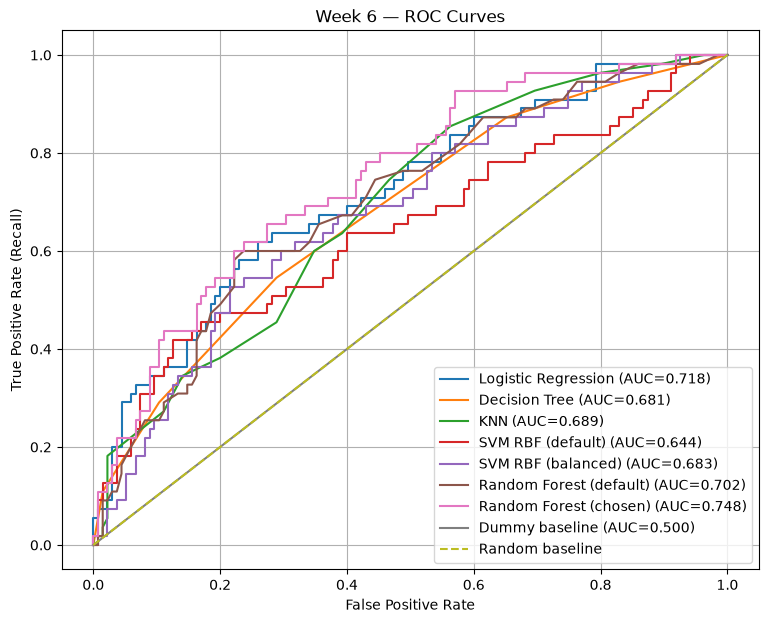

In [78]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

roc_specs = [
    ("Logistic Regression", logreg, x_test_scaled),
    ("Decision Tree", dtree, x_test),
    ("KNN", knn, x_test_scaled),
    ("SVM RBF (default)", svm_rbf, x_test_scaled),
    ("SVM RBF (balanced)", svm_rbf_bal, x_test_scaled),
    ("Random Forest (default)", rf, x_test),
    ("Random Forest (chosen)", rf_best, x_test),
    ("Dummy baseline", dummy_model, x_test)
]

plt.figure(figsize=(9, 7))
for name, model, Xt in roc_specs:
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(Xt)[:, 1]
    else:
        scores = model.decision_function(Xt)
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Week 6 — ROC Curves")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


### T40 — Explain SVM and Random Forest in plain words

**Support Vector Machine (SVM):** An SVM tries to draw a boundary that separates two groups of patients. It pays special attention to the examples closest to that boundary because they help determine where it should go. The model predicts a patient's group based on which side of the boundary the patient falls on. Balanced class weights can make it pay more attention to diabetic patients.

**Random Forest:** A Random Forest combines the decisions of many decision trees. Each tree learns from a slightly different sample of the training data and may consider different features. The forest combines their predictions to produce one final prediction. This can make it more stable than relying on one tree, but its performance still needs to be measured.

### T41 — Note what surprised you

In [79]:
print("Highest recall:")
print(results.loc[results["recall"].idxmax(),
                  ["model", "recall", "TP", "FN"]])
print("\\nHighest accuracy:")
print(results.loc[results["accuracy"].idxmax(),
                  ["model", "accuracy", "recall"]])
print("\\nHighest AUC:")
print(results.loc[results["auc"].idxmax(),
                  ["model", "auc", "recall"]])
print("\\nHighest F1:")
print(results.loc[results["f1"].idxmax(),
                  ["model", "f1", "precision", "recall"]])


Highest recall:
model     Random Forest (depth=5, balanced)
recall                             0.654545
TP                                       36
FN                                       19
Name: 11, dtype: object
\nHighest accuracy:
model       Logistic Regression (default)
accuracy                         0.752632
recall                           0.290909
Name: 0, dtype: object
\nHighest AUC:
model     Random Forest (depth=5, balanced)
auc                                0.747609
recall                             0.654545
Name: 11, dtype: object
\nHighest F1:
model        Random Forest (depth=5, balanced)
f1                                    0.545455
precision                             0.467532
recall                                0.654545
Name: 11, dtype: object


### T43 — Save the full comparison table

In [80]:
results.to_csv(r"C:\Users\USER\Desktop\5th sem\project1_daibatise\reports\ajlan_p1W6_results.csv")
print("Saved comparison table to ajlan_p1W6_results.csv")


Saved comparison table to ajlan_p1W6_results.csv
